# Student Performance ML Project

**📝 Problem Statement**

* The objective of this project is to build an end-to-end predictive regression model that forecasts a student's final math score based on their demographic background and foundational academic markers. 
* By leveraging demographic variables (gender, race/ethnicity, parental level of education), institutional support markers (lunch, test preparation course), and core literacy parameters (reading score, writing score), the model uncovers key drivers of academic success. 
* This predictive framework enables educational institutions to proactively flag students who may require targeted mathematical interventions, allowing for personalized support strategies before final examinations

**Step 1: Import Libraries**

In [1]:
# System and Data manipulation
import joblib

# Visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

# feature selection
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer

# Regression Models
from sklearn.linear_model import LinearRegression

# Regression Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Preprocessing & Selection
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor


**Step 2: Load Dataset**

In [2]:
df = pd.read_csv('StudentsPerformance.csv')

**Step 3: Understand Your Data (EDA)**

In [5]:
print("[First 5 Rows Preview]:")
df.head()

[First 5 Rows Preview]:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.groupby("gender")["math score"].mean()

gender
female    63.633205
male      68.728216
Name: math score, dtype: float64

In [7]:
print(f"[Dataset Dimensions (Rows, Columns)]: {df.shape}")

[Dataset Dimensions (Rows, Columns)]: (1000, 8)


In [24]:
print("\n[Data Types]:\n", df.dtypes)


[Data Types]:
 gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object


In [20]:
print(f"[Unique rows]: \n{df.nunique()}")

[Unique rows]: 
gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64


In [22]:
print(f"Columns: \n{df.columns}")

Columns: 
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')


In [23]:
print("\n[Data Types and Structural Check]:\n")
df.info()


[Data Types and Structural Check]:

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [9]:
print("[Descriptive Statistical Summary]:")
df.describe().T


[Descriptive Statistical Summary]:


,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.089,15.163080,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.169,14.600192,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


In [10]:
# Target Variable Analysis (Math Score Distribution Profile)
print(f"\n[Target Skewness Profile]: {df['math score'].skew():.2f}")


[Target Skewness Profile]: -0.28


**Step 4: Data Cleaning**

In [11]:
# 1. Remove Duplicates
print(f"Duplicate rows identified: {df.duplicated().sum()}")
df = df.drop_duplicates()

Duplicate rows identified: 0


In [ ]:
# 2. Remove Unwanted Columns
# there no unwanted col

In [49]:
# 3. Check for Missing Values 
print("Missing values per parameter:\n",df.isnull().sum())

Missing values per parameter:
 gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [ ]:
# 4. Fix Data Types
# No need

In [50]:
# 5. Fix proper col names

rename_dict = {
    'race/ethnicity': 'ethnicity',
    'parental level of education': 'parent_education',
    'lunch': 'lunch_type',
    'test preparation course': 'test_prep',
    'math score': 'math_score',
    'reading score': 'reading_score',
    'writing score': 'writing_score'
}

# Apply changes to your dataframe
df = df.rename(columns=rename_dict)

<Axes: >

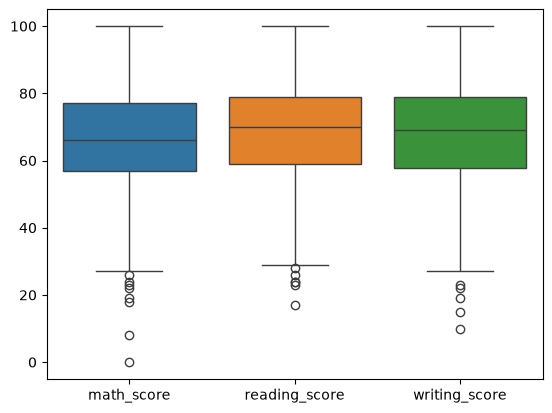

In [51]:
# 5. Remove outliers

sns.boxplot(df[['math_score', 'reading_score','writing_score']])

In [52]:
cols = df.select_dtypes(include=[int,float]).columns.tolist()
for i,col in enumerate(cols,start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    before_outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"\n{i}. {col}:")
    print("Before outliers: ",len(before_outliers))
    df[col] = df[col].clip(lower, upper)
    after_outliers = df[(df[col] < lower) | (df[col] > upper)]
    print("After outliers: ",len(after_outliers))


1. math_score:
Before outliers:  8
After outliers:  0

2. reading_score:
Before outliers:  6
After outliers:  0

3. writing_score:
Before outliers:  5
After outliers:  0


**Verify:**

<Axes: >

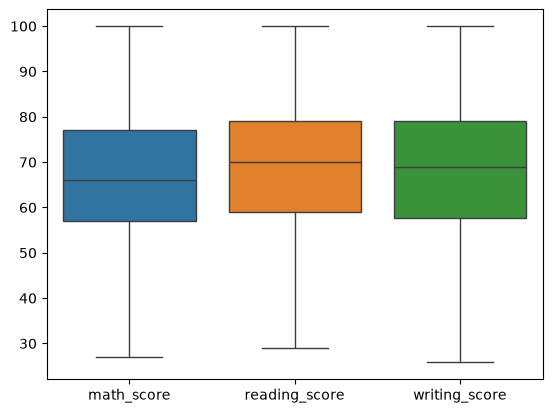

In [53]:
sns.boxplot(df[df.select_dtypes(include=[int,float]).columns.tolist()])

**Step 5: Feature Engineering**

In [ ]:
# total score
df['Literacy_Total'] = df['reading_score'] + df['writing_score']

df['Reading_Writing_Ratio'] = df['reading_score'] / (df['writing_score'] + 1)

In [68]:
df['average_score']=(df['math_score']+df['reading_score']+df['writing_score'])/3

def performance(avg):
    if avg >= 80:
        return "Excellent"
    elif avg >= 60:
        return "Good"
    else:
        return "Poor"
# performance category
df['performance'] = df['average_score'].apply(performance)

**Step 6: Data Visualization**

Univariate:

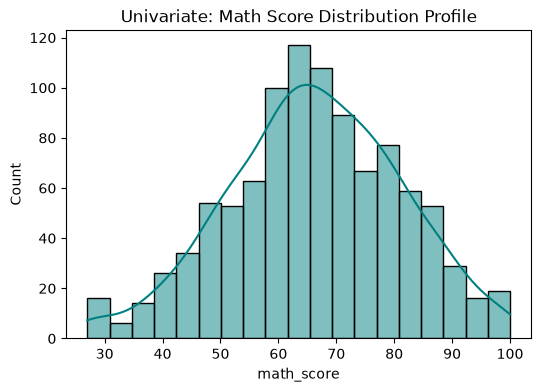

In [55]:
# 1. Univariate: Histogram (Math Score Distribution)
plt.figure(figsize=(6, 4))
sns.histplot(df['math_score'], kde=True, color='teal')
plt.title('Univariate: Math Score Distribution Profile')
plt.show()

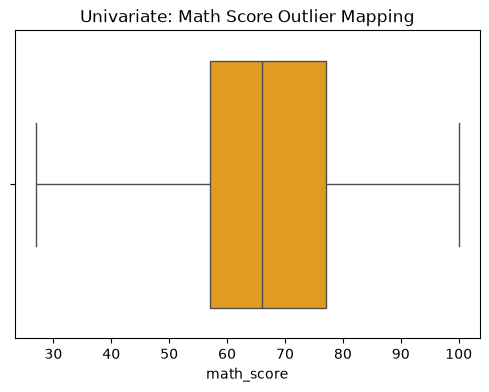

In [56]:
# 2. Univariate: Boxplot (Check for outliers in distribution spreads)
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['math_score'], color='orange')
plt.title('Univariate: Math Score Outlier Mapping')
plt.show()

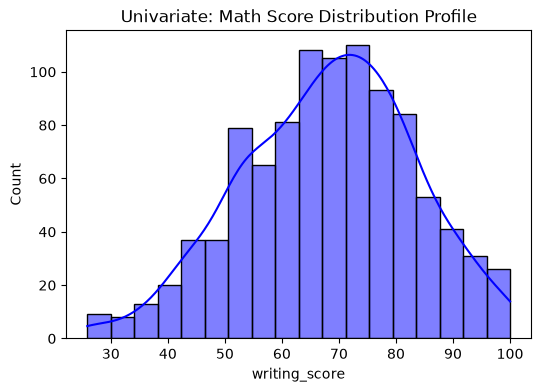

In [58]:
# 2. Univariate: Boxplot (Check for outliers in distribution spreads)
plt.figure(figsize=(6, 4))
sns.histplot(df['writing_score'], kde=True, color='blue')
plt.title('Univariate: Math Score Distribution Profile')
plt.show()

Bivariate & Multivariate:

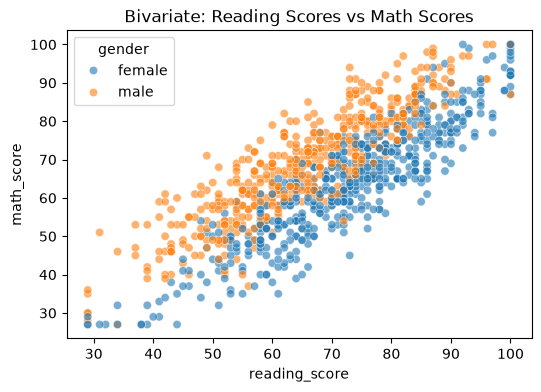

In [60]:
# 3. Bivariate: Scatterplot (Reading vs Math split by Gender)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='reading_score', y='math_score', hue='gender', alpha=0.6)
plt.title('Bivariate: Reading Scores vs Math Scores')
plt.show()

Correlation analysis:

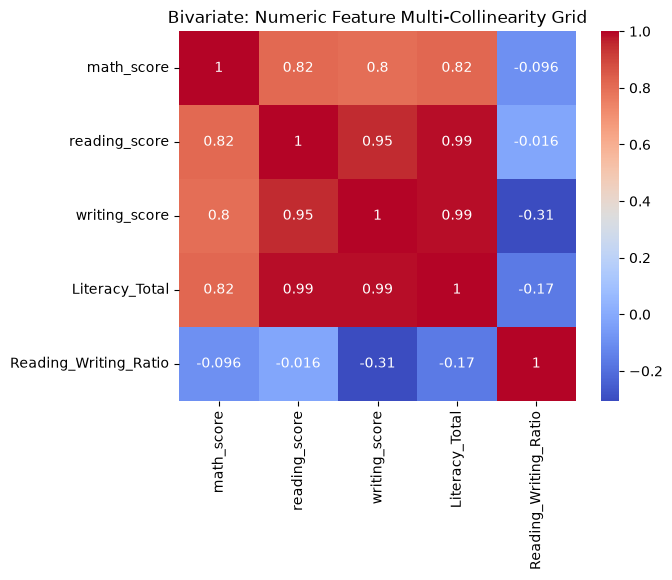

In [ ]:
# 4. Bivariate: Correlation Matrix Heatmap
sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True,cmap='coolwarm')
plt.title('Bivariate: Numeric Feature Multi-Collinearity Grid')
plt.show()

**Step 7: Define Features (X) and Target (y)**

In [70]:
X = df.drop(columns=['math_score'])
y = df['math_score']

numeric_cols = X.select_dtypes(include=[int,float]).columns.tolist()
categorical_cols = X.select_dtypes(include=['str', 'category']).columns.tolist()

**Step 8: Train-Test Split**

In [71]:
# Partition the data cleanly into 80% Training and 20% Testing subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

X_train Shape: (800, 11) | X_test Shape: (200, 11)


**Step 9: Preprocessing Pipeline**

In [72]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

**Step 10: Feature Selection**

In [73]:
# Initialize VarianceThreshold
selector = VarianceThreshold(threshold=0.01)

# Fit and transform the data
X_train_sele = selector.fit_transform(X_train_processed)
X_test_sele = selector.fit_transform(X_test_processed)

print("Original X Train shape:", X_train_processed.shape)
print("Reduced X Train shape:", X_train_sele.shape)
print("Reduced X Test shape:", X_test_sele.shape)

Original X Train shape: (800, 25)
Reduced X Train shape: (800, 25)
Reduced X Test shape: (200, 25)


**Step 11 & 12: Train Models & Regression Metrics**

In [74]:
regression_suite = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
}

for name, model in regression_suite.items():
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    
    # Calculate performance metrics
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    
    print(f"[{name}] -> R2 Score: {r2*100:.2f}% | MAE: {mae:.2f} | RMSE: {rmse:.2f}")


[Linear Regression] -> R2 Score: 100.00% | MAE: 0.00 | RMSE: 0.00
[Decision Tree] -> R2 Score: 93.45% | MAE: 2.85 | RMSE: 3.85
[Random Forest] -> R2 Score: 96.67% | MAE: 2.06 | RMSE: 2.74
[XGBoost Regressor] -> R2 Score: 97.26% | MAE: 1.84 | RMSE: 2.49


**Step 13: Cross Validation**

In [ ]:
print("--- 14. CROSS VALIDATION ---")

# Verify generalization stability on our pipeline baseline using 3-Folds
linear_validator = LinearRegression()
cv_scores = cross_val_score(linear_validator, X_train_processed, y_train, cv=3, scoring='r2')

print(f"3-Fold Cross Validation Individual R2 Matrix: {cv_scores}")
print(f"Mean Generalization R2 Accuracy: {cv_scores.mean()*100:.2f}%")

--- 14. CROSS VALIDATION ---
3-Fold Cross Validation Individual R2 Matrix: [1. 1. 1.]
Mean Generalization R2 Accuracy: 100.00%


**Step 14: Hyperparameter Tuning**

In [ ]:
linear_tuning_target = LinearRegression()

param_distributions = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

random_search = RandomizedSearchCV(
    estimator=linear_tuning_target, 
    param_distributions=param_distributions,
    n_iter=4,                       
    cv=2,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_processed, y_train)
best_tuned_regressor = random_search.best_estimator_

print("Optimal Hyperparameter Configurations Found:", random_search.best_params_)


Optimal Hyperparameter Configurations Found: {'positive': False, 'fit_intercept': True}


**Step 15: Feature Importance**

In [80]:
features = preprocessor.get_feature_names_out()

# Build the importance list using the linear model's coefficients (.coef_)
importance = pd.DataFrame({
    'Feature': [name.split('__')[-1] for name in features], # Cleans the names
    'Importance': best_tuned_regressor.coef_                 # Uses .coef_ for linear models
})

importance['Abs_Importance'] = importance['Importance'].abs()
importance = importance.sort_values(by='Abs_Importance', ascending=False).drop(columns=['Abs_Importance'])

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(importance.to_string(index=False))



--- TOP FEATURE IMPORTANCE SCORES ---
                            Feature    Importance
                      average_score  4.212280e+01
                      writing_score -9.938189e+00
                     Literacy_Total -9.850159e+00
                      reading_score -9.534379e+00
              Reading_Writing_Ratio  3.486381e-14
                      gender_female  2.423174e-14
                   performance_Poor -2.310864e-14
                        gender_male  1.751265e-14
                lunch_type_standard  1.437044e-14
      parent_education_some college -1.421720e-14
            lunch_type_free/reduced  1.305207e-14
 parent_education_bachelor's degree -1.297145e-14
                  ethnicity_group D  9.229420e-15
                  ethnicity_group E -8.108477e-15
                   performance_Good -7.764701e-15
                  ethnicity_group A -7.558099e-15
   parent_education_master's degree  6.286565e-15
parent_education_associate's degree  5.929060e-15
           

**Using XgBoost:**

In [84]:
xg_boost = XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
xg_boost.fit(X_train_processed, y_train)

raw_features = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    'Feature': raw_features,
    'Importance': xg_boost.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES (XGBoost) ---")
print(importance.to_string(index=False))



--- TOP FEATURE IMPORTANCE SCORES (XGBoost) ---
                                 Feature  Importance
                      num__average_score    0.585004
                      cat__gender_female    0.234540
            cat__lunch_type_free/reduced    0.037743
                     num__Literacy_Total    0.035641
                  cat__ethnicity_group E    0.022732
                cat__test_prep_completed    0.018460
                      num__reading_score    0.014931
                      num__writing_score    0.008146
              num__Reading_Writing_Ratio    0.007617
      cat__parent_education_some college    0.005664
                  cat__ethnicity_group C    0.004812
                  cat__ethnicity_group A    0.004653
       cat__parent_education_high school    0.003635
  cat__parent_education_some high school    0.003421
                  cat__ethnicity_group D    0.003197
cat__parent_education_associate's degree    0.003099
   cat__parent_education_master's degree    0.0028

**Step 16: Final Pipeline Production**

In [85]:
print("Comprehensive automated modeling pipeline constructed successfully!")
model_artifact_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', best_tuned_regressor)
])

model_artifact_pipeline.fit(X_train, y_train)


Comprehensive automated modeling pipeline constructed successfully!


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['gender','ethnicity','parent_education',...,'Reading_Writing_Ratio', 'average_score','performance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passe

**Step 17: Save Model & Load Model**

In [88]:
model_artifact = {
    "model_pipeline": model_artifact_pipeline,
    "feature_names": X.columns.tolist()
}

joblib.dump(model_artifact, "linear_model.pkl")
print("Production artifact saved successfully as 'linear_model.pkl'")

Production artifact saved successfully as 'linear_model.pkl'


In [87]:
loaded_bundle = joblib.load("linear_model.pkl")
production_ready_pipeline = loaded_bundle["model_pipeline"]
print("Model validation verified successfully. Code ready for production server deployment.")


Model validation verified successfully. Code ready for production server deployment.
